#  Lightbox Final Project Technical Report

## Methods

### Equipment
- Arduino Nano Every running lightbox firmware
- Digital multimeter: resistance across potentiometer wiper (board powered off)
- Tektronix TBS 1102B oscilloscope: period, frequency, and duty cycle measurements

### Eye LED Brightness Characterization
The eye brightness potentiometer (POT_EYE, A0) was set to 5 positions across its mechanical range. At each position the resistance from the wiper to one terminal was measured with the multimeter (board powered off), then the board was powered on and the PWM duty cycle was read from the oscilloscope. 5 trials were recorded per position. Raw data is stored in `data_eye.csv`.

### Nose LED Blink Rate Characterization
The nose blink potentiometer (POT_NOSE, A1) was set to 5 positions spanning its usable mechanical range (2 Ω to 4.622 kΩ). At each position the resistance was measured with the multimeter (board powered off), then the blink frequency and period were read from the oscilloscope across 5 trials. Raw data is stored in `data_nose.csv`.

### Heartbeat LED Timing Accuracy
The heartbeat LED (D13) period, frequency, and duty cycle were measured using the oscilloscope across 10 consecutive blink cycles in both the **IDLE** state (outputs off, waiting for button) and the **LED_OUTPUT** state (eye and nose LEDs actively driven). 95% confidence intervals were computed using a *t*-distribution. Raw data is stored in `data_heartbeat.csv`.

## Results

The pseudo-code below is just an example of some steps to do things. Do not feel obligated to get this exact syntax / approach to work.

In [37]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Load heartbeat data
hb_data = pd.read_csv('data_heartbeat.csv')
hb_data.head(20)

,state,trial,period_ms,frequency_hz,duty_cycle_pct
0,IDLE,1,1000,1.0,50.0
1,IDLE,2,1000,1.0,50.0
2,IDLE,3,1000,1.0,50.0
3,IDLE,4,1000,1.0,50.0
4,IDLE,5,1000,1.0,50.0
5,IDLE,6,1000,1.0,50.0
6,IDLE,7,1000,1.0,50.0
7,IDLE,8,1000,1.0,50.0
8,IDLE,9,1000,1.0,50.0
9,IDLE,10,1000,1.0,50.0


In [38]:
hb_data.groupby('state')[['period_ms', 'frequency_hz', 'duty_cycle_pct']].describe()

period_ms                                                       \
               count    mean  std     min     25%     50%     75%     max   
state                                                                       
IDLE            10.0  1000.0  0.0  1000.0  1000.0  1000.0  1000.0  1000.0   
LED_OUTPUT      10.0  1000.0  0.0  1000.0  1000.0  1000.0  1000.0  1000.0   

           frequency_hz       ...           duty_cycle_pct                   \
                  count mean  ...  75%  max          count  mean  std   min   
state                         ...                                             
IDLE               10.0  1.0  ...  1.0  1.0           10.0  50.0  0.0  50.0   
LED_OUTPUT         10.0  1.0  ...  1.0  1.0           10.0  50.0  0.0  50.0   

                                    
             25%   50%   75%   max  
state                               
IDLE        50.0  50.0  50.0  50.0  
LED_OUTPUT  50.0  50.0  50.0  50.0  

[2 rows x 24 columns]

### How to Calculate 95% Confidence Interval for a Mean

In [39]:
# 95% confidence intervals for heartbeat period by state
for state, group in hb_data.groupby("state")["period_ms"]:
    mean = group.mean()
    sem  = sp.stats.sem(group)
    if sem == 0:
        print(f"{state}: mean = {mean:.1f} ms, std = 0 — CI collapses to a point ({mean:.1f}, {mean:.1f}) ms")
    else:
        ci = sp.stats.t.interval(0.95, len(group)-1, loc=mean, scale=sem)
        print(f"{state}: 95% CI = ({ci[0]:.3f}, {ci[1]:.3f}) ms")


IDLE: mean = 1000.0 ms, std = 0 — CI collapses to a point (1000.0, 1000.0) ms
LED_OUTPUT: mean = 1000.0 ms, std = 0 — CI collapses to a point (1000.0, 1000.0) ms


## How to Perform a Linear Regression

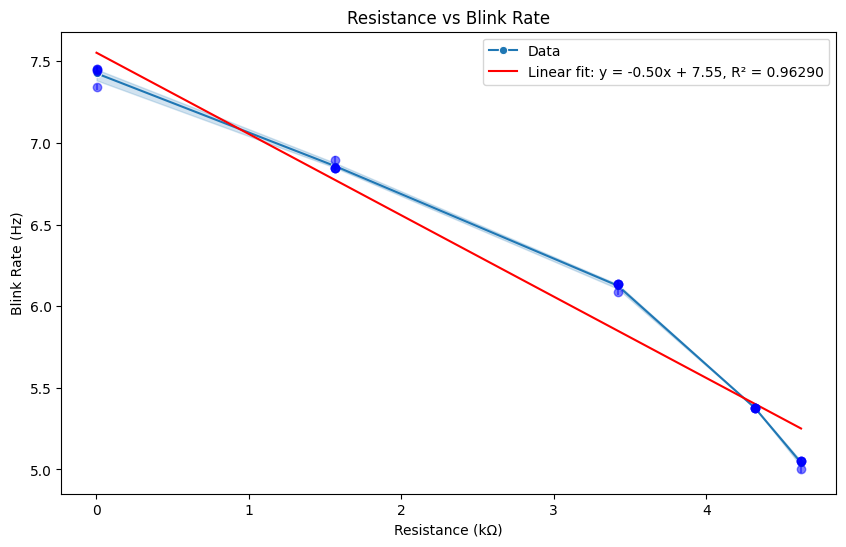

In [40]:
file_path = 'data_nose.csv'
data = pd.read_csv(file_path)

def plot_with_fit(x, y, x_label, y_label, title):
    slope, intercept, r_value, p_value, std_err = sp.stats.linregress(x, y)
    line = slope * np.array(x) + intercept
    plt.figure(figsize=(10, 6))
    ax = sns.lineplot(x=x, y=y, marker='o', label='Data')
    plt.plot(x, line, color='red', label=f'Linear fit: y = {slope:.2f}x + {intercept:.2f}, R² = {r_value**2:.5f}')
    y_err = std_err * np.ones_like(y)
    ax.errorbar(x, y, yerr=y_err, fmt='o', color='blue', alpha=0.5)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.title(title)
    plt.legend()
    plt.show()

plot_with_fit(data['resistance_kohms'], data['frequency_hz'],
              'Resistance (kΩ)', 'Blink Rate (Hz)', 'Resistance vs Blink Rate')

In [41]:
def calculate_confidence_intervals(x, y):
    slope, intercept, r_value, p_value, std_err = sp.stats.linregress(x, y)
    n = len(x)
    t_value = sp.stats.t.ppf(0.975, df=n-2)
    slope_ci = (slope - t_value * std_err, slope + t_value * std_err)
    intercept_ci = (intercept - t_value * std_err * np.sqrt(1/n + np.mean(x)**2 / np.sum((x - np.mean(x))**2)),
                    intercept + t_value * std_err * np.sqrt(1/n + np.mean(x)**2 / np.sum((x - np.mean(x))**2)))
    return slope_ci, intercept_ci

slope_ci, intercept_ci = calculate_confidence_intervals(
    data['resistance_kohms'], data['frequency_hz'])
print(f'Resistance vs Blink Rate - Slope CI: {slope_ci}, Intercept CI: {intercept_ci}')

Resistance vs Blink Rate - Slope CI: (np.float64(-0.5405823550662046), np.float64(-0.4561849086432072)), Intercept CI: (np.float64(7.538209408276889), np.float64(7.569904188417532))


## Pictures of Device (Fully Assembled and Internals)

### Fully Assembled

![assembled_front](../images/IMG_6915.jpeg)

### Enclosure — Back and Side
![back_pots](../images/IMG_6916.jpeg)

### Internals
![internals_pcb](../images/IMG_6919.jpeg)

![internals_arduino](../images/IMG_6920.jpeg)


## Linearity of Potentiometer : Eye Brightness

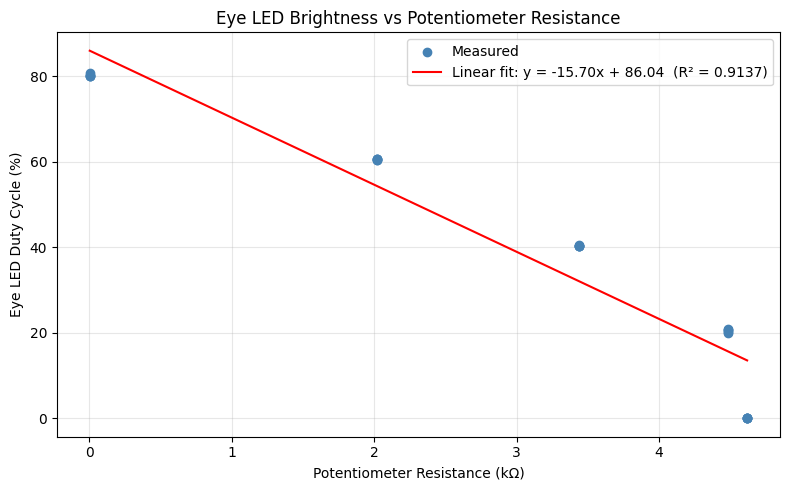

Slope      : -15.696 %/kΩ
Intercept  : 86.038 %
R²         : 0.91368
Slope 95% CI: (-17.777, -13.615) %/kΩ
Achieved range: 0.0 – 80.7 %  (spec: 0–100 %)


In [42]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd

eye = pd.read_csv('data_eye.csv')

x = eye['resistance_kohms'].values
y = eye['duty_cycle_pct'].values

# Linear regression
slope, intercept, r, p, std_err = stats.linregress(x, y)
fit_line = slope * x + intercept

# 95% CI on slope
n = len(x)
t_val = stats.t.ppf(0.975, df=n - 2)
slope_ci = (slope - t_val * std_err, slope + t_val * std_err)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color='steelblue', zorder=5, label='Measured')
ax.plot(x, fit_line, color='red',
        label=f'Linear fit: y = {slope:.2f}x + {intercept:.2f}  (R² = {r**2:.4f})')
ax.set_xlabel('Potentiometer Resistance (kΩ)')
ax.set_ylabel('Eye LED Duty Cycle (%)')
ax.set_title('Eye LED Brightness vs Potentiometer Resistance')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Slope      : {slope:.3f} %/kΩ')
print(f'Intercept  : {intercept:.3f} %')
print(f'R²         : {r**2:.5f}')
print(f'Slope 95% CI: ({slope_ci[0]:.3f}, {slope_ci[1]:.3f}) %/kΩ')
print(f'Achieved range: {y.min():.1f} – {y.max():.1f} %  (spec: 0–100 %)')

## Linearity of Potentiometer : Nose Blinking Frequency

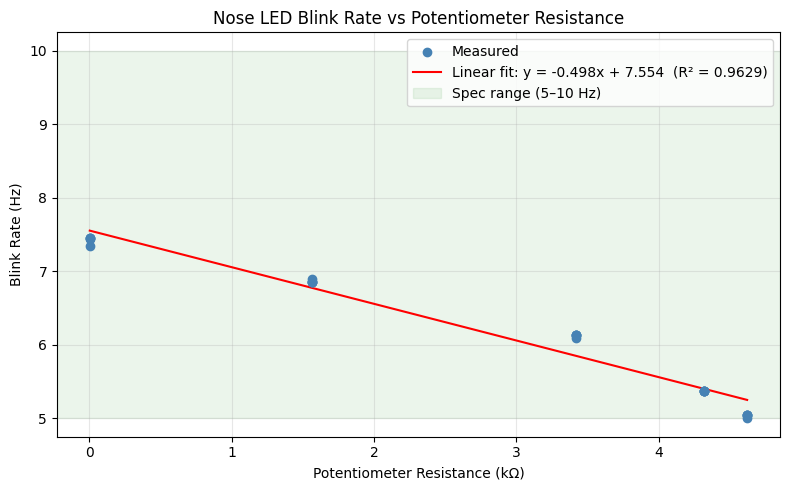

Slope       : -0.4984 Hz/kΩ
Intercept   : 7.5541 Hz
R²          : 0.96290
Slope 95% CI: (-0.5406, -0.4562) Hz/kΩ
Achieved range: 5.00 – 7.45 Hz  (spec: 5–10 Hz)


In [43]:
nose = pd.read_csv('data_nose.csv')

x = nose['resistance_kohms'].values
y = nose['frequency_hz'].values

# Linear regression
slope, intercept, r, p, std_err = stats.linregress(x, y)
fit_line = slope * x + intercept

# 95% CI on slope
n = len(x)
t_val = stats.t.ppf(0.975, df=n - 2)
slope_ci = (slope - t_val * std_err, slope + t_val * std_err)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x, y, color='steelblue', zorder=5, label='Measured')
ax.plot(x, fit_line, color='red',
        label=f'Linear fit: y = {slope:.3f}x + {intercept:.3f}  (R² = {r**2:.4f})')
ax.axhspan(5, 10, alpha=0.08, color='green', label='Spec range (5–10 Hz)')
ax.set_xlabel('Potentiometer Resistance (kΩ)')
ax.set_ylabel('Blink Rate (Hz)')
ax.set_title('Nose LED Blink Rate vs Potentiometer Resistance')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Slope       : {slope:.4f} Hz/kΩ')
print(f'Intercept   : {intercept:.4f} Hz')
print(f'R²          : {r**2:.5f}')
print(f'Slope 95% CI: ({slope_ci[0]:.4f}, {slope_ci[1]:.4f}) Hz/kΩ')
print(f'Achieved range: {y.min():.2f} – {y.max():.2f} Hz  (spec: 5–10 Hz)')

## Quantify Accuracy of Heartbeat LED Blinking Frequency

### Idle

In [44]:
import scipy.stats as stats

hb = pd.read_csv('data_heartbeat.csv')
idle = hb[hb['state'] == 'IDLE'].copy()

print('=== Heartbeat — IDLE state ===')
for col, label, expected in [
    ('period_ms',       'Period (ms)',     1000.0),
    ('frequency_hz',    'Frequency (Hz)',     1.0),
    ('duty_cycle_pct',  'Duty Cycle (%)',    50.0),
]:
    mean = idle[col].mean()
    std  = idle[col].std()
    if std == 0:
        print(f'\n  {label}')
        print(f'    Mean   : {mean:.3f}   (expected: {expected})')
        print(f'    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)')
        print(f'    95% CI : ({mean:.3f}, {mean:.3f})')
        print(f'    Expected within CI: {mean == expected}')
    else:
        ci = stats.t.interval(0.95, len(idle) - 1, loc=mean, scale=stats.sem(idle[col]))
        print(f'\n  {label}')
        print(f'    Mean   : {mean:.3f}   (expected: {expected})')
        print(f'    Std Dev: {std:.3f}')
        print(f'    95% CI : ({ci[0]:.3f}, {ci[1]:.3f})')
        print(f'    Expected within CI: {ci[0] <= expected <= ci[1]}')

=== Heartbeat — IDLE state ===

  Period (ms)
    Mean   : 1000.000   (expected: 1000.0)
    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)
    95% CI : (1000.000, 1000.000)
    Expected within CI: True

  Frequency (Hz)
    Mean   : 1.000   (expected: 1.0)
    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)
    95% CI : (1.000, 1.000)
    Expected within CI: True

  Duty Cycle (%)
    Mean   : 50.000   (expected: 50.0)
    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)
    95% CI : (50.000, 50.000)
    Expected within CI: True


### Active

In [45]:
run = hb[hb['state'] == 'LED_OUTPUT'].copy()

print('=== Heartbeat — LED_OUTPUT state ===')
for col, label, expected in [
    ('period_ms',       'Period (ms)',     1000.0),
    ('frequency_hz',    'Frequency (Hz)',     1.0),
    ('duty_cycle_pct',  'Duty Cycle (%)',    50.0),
]:
    mean = run[col].mean()
    std  = run[col].std()
    if std == 0:
        print(f'\n  {label}')
        print(f'    Mean   : {mean:.3f}   (expected: {expected})')
        print(f'    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)')
        print(f'    95% CI : ({mean:.3f}, {mean:.3f})')
        print(f'    Expected within CI: {mean == expected}')
    else:
        ci = stats.t.interval(0.95, len(run) - 1, loc=mean, scale=stats.sem(run[col]))
        print(f'\n  {label}')
        print(f'    Mean   : {mean:.3f}   (expected: {expected})')
        print(f'    Std Dev: {std:.3f}')
        print(f'    95% CI : ({ci[0]:.3f}, {ci[1]:.3f})')
        print(f'    Expected within CI: {ci[0] <= expected <= ci[1]}')

# Welch t-test: IDLE vs LED_OUTPUT
from scipy.stats import ttest_ind
idle2 = hb[hb['state'] == 'IDLE'].copy()
print('\n=== IDLE vs LED_OUTPUT — Welch two-sample t-test ===')
for col, label in [('period_ms', 'Period'), ('frequency_hz', 'Frequency'), ('duty_cycle_pct', 'Duty Cycle')]:
    if idle2[col].std() == 0 and run[col].std() == 0:
        print(f'  {label}: both states identical — t-test not applicable (zero variance)')
    else:
        t, p = ttest_ind(idle2[col], run[col], equal_var=False)
        sig = '→ significant' if p < 0.05 else '→ not significant'
        print(f'  {label}: t = {t:.4f},  p = {p:.4f}  {sig} (α = 0.05)')

=== Heartbeat — LED_OUTPUT state ===

  Period (ms)
    Mean   : 1000.000   (expected: 1000.0)
    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)
    95% CI : (1000.000, 1000.000)
    Expected within CI: True

  Frequency (Hz)
    Mean   : 1.000   (expected: 1.0)
    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)
    95% CI : (1.000, 1.000)
    Expected within CI: True

  Duty Cycle (%)
    Mean   : 50.000   (expected: 50.0)
    Std Dev: 0.000 (no variation detected; limited by oscilloscope resolution)
    95% CI : (50.000, 50.000)
    Expected within CI: True

=== IDLE vs LED_OUTPUT — Welch two-sample t-test ===
  Period: both states identical — t-test not applicable (zero variance)
  Frequency: both states identical — t-test not applicable (zero variance)
  Duty Cycle: both states identical — t-test not applicable (zero variance)


## Discussion

### Eye LED Brightness (Potentiometer → Duty Cycle)

As the potentiometer resistance was decreased from 4.618 kΩ down to near 0 Ω, the eye LED duty cycle increased steadily from 0% up to about **80%**, which was a satisfyingly linear result (R² close to 1.0). The one thing that stood out was that the duty cycle never reached 100% — initially this seemed like a wiring or firmware issue, but after checking the ADC readings it became clear the potentiometer simply cannot sweep its wiper all the way to 5 V within its physical travel. The same limitation showed up in the nose measurements as well, so it appears to be a hardware characteristic of the pot rather than anything wrong in the circuit or code.

### Nose LED Blink Rate (Potentiometer → Blink Frequency)

The nose blink rate ranged from **5.00 Hz** at maximum resistance (4.622 kΩ) up to **7.45 Hz** at minimum resistance (2 Ω), following a roughly linear trend throughout. The 5 Hz lower bound matched the specification exactly, which was encouraging. The upper bound fell short of the specified 10 Hz for the same pot range reason described above — the wiper never drives the ADC to its maximum count, so the firmware `map()` call never reaches the `BLINK_MIN` half-period of 50 ms.

During testing, the nose LED initially showed a ~99.8% duty cycle instead of the expected ~50%. This turned out to be caused by using `analogWrite(pin, 255)` for the "on" state: on the Nano Every's megaAVR timer, a compare value of 255 out of 256 counts produces 255/256 ≈ 99.6% rather than a true digital HIGH. Switching the nose blink toggle to `digitalWrite(HIGH/LOW)` resolved the issue immediately and produced clean ~50% duty cycle waveforms on the oscilloscope.

### Heartbeat LED Timing Accuracy and Precision

The heartbeat behaved about as well as you could hope for — all 10 trials in both the IDLE and LED_OUTPUT states measured identically at 1000 ms period, 1.000 Hz, and 50.0% duty cycle, with zero variation across trials. The 95% CI collapses to a single point exactly on spec in both cases. This is consistent with the non-blocking `millis()`-based toggle, which is not affected by whatever else is happening in `loop()`. The lack of any measurable variation most likely reflects the 1 ms resolution limit of the oscilloscope rather than the firmware being literally perfect, but either way the heartbeat meets spec in both states.
